In [2]:
import cv2
import os
import numpy as np
from tqdm import tqdm
import h5py
import matplotlib.pyplot as plt

5, 13번데이터 문제

데이터 경로 : /nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/videos/A007_20250612/NIR
 총 프레임 수 : 120592 


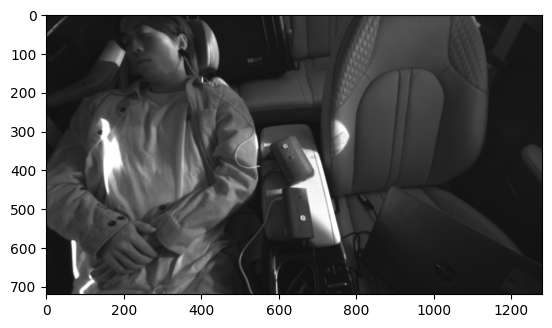

In [3]:
# 1. 경로 설정 (절대 경로 사용)
base_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/videos/'
people = [f for f in os.listdir(base_dir)]
##########subject 설정##############
subject_num = 1 ### subject 설정 ####
vid_dir = os.path.join(base_dir, people[subject_num],'NIR')
print(f"데이터 경로 : {vid_dir}")

save_folder = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data' 
##########저장 파일 이름 설정##########
output_name = f'nirp_cna_video_[{subject_num}].h5'
save_path = os.path.join(save_folder, output_name)

clahe = cv2.createCLAHE(clipLimit=6.0, tileGridSize=(8, 8))


# 저장 폴더가 없으면 생성
#if not os.path.exists(save_folder):
#    os.makedirs(save_folder)

plt.imshow(cv2.imread(os.path.join(vid_dir,'frame018000.png')))

print(f" 총 프레임 수 : {len(os.listdir(vid_dir))} ")

In [10]:
vid_dir_2 = os.path.join(base_dir, people[subject_num],'NIR_cut')
print(len(os.listdir(vid_dir)))
print(len(os.listdir(vid_dir_2)))

117465
117465


In [9]:
# 파일 목록 정렬
files = sorted([f for f in os.listdir(vid_dir) if f.endswith('.png')])

# 영상 자르는 픽셀 위치
r_start = 0
r_end = 220
c_start = 100
c_end = 450

# 2. 영상 크기 확인\
first_img = cv2.imread(os.path.join(vid_dir, files[0]), cv2.IMREAD_GRAYSCALE)
img_cut = first_img[r_start:r_end,c_start:c_end]
h, w = img_cut.shape
file_use = files[18000:27000]

# 3. VideoWriter 설정 (한 번만 정의!)
fourcc = cv2.VideoWriter_fourcc(*'mp4v') 
out = cv2.VideoWriter(save_path, fourcc, 30, (w, h), isColor=True)

print(f"작업 시작: {save_path}에 저장 중...")

# 4. 프레임 기록
count = 0
for f in tqdm(file_use):
    img = cv2.imread(os.path.join(vid_dir, f), cv2.IMREAD_GRAYSCALE)
    img_c = img[r_start:r_end,c_start:c_end]
    if img_c is None: continue

    #clahe 변환
    #img_c = clahe.apply(img_c)

    # rPPG 모델 입력을 위해 RGB(3채널)로 복제
    img_rgb = cv2.cvtColor(img_c, cv2.COLOR_GRAY2RGB)
    out.write(img_rgb)
    count += 1

    
# 5. [가장 중요] 파일 작성 완료 및 닫기
out.release() 

if count > 0:
    print(f"\n성공! {count}개 프레임이 저장되었습니다.")
    print(f"경로: {save_path}")
else:
    print("\n경고: 저장된 프레임이 없습니다. 밝기 임계값을 확인하세요.")

작업 시작: /nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/videos/KM_preprocess_data/nirp_cna_video_[2].h5에 저장 중...


  0%|          | 1/9000 [00:00<1:09:16,  2.16it/s]


KeyboardInterrupt: 

In [15]:
export HDF5_USE_FILE_LOCKING=FALSE

SyntaxError: invalid syntax (1403205308.py, line 1)

In [14]:
#h5 자료형으로 저장 

r_start, r_end, c_start, c_end = 0, 220, 100, 450 ## crop 좌표 설정
h, w = (r_end - r_start) , (c_end - c_start)

files = sorted([f for f in os.listdir(vid_dir)])
num_frames = len(files) # 프레임수 확인

print(f"동영상 생성 시작 {save_path} 경로에 생성 중 . . . ")

with h5py.File(save_path, 'w') as f :
    
    dset = f.create_dataset('video', (num_frames, h, w, 1), dtype = 'uint8', compression = 'gzip' )

    for i, f_name in enumerate(tqdm(files)) : 
        img = cv2.imread( os.path.join(vid_dir, f_name), cv2.IMREAD_UNCHANGED)
        if img is None : continue

        img_c = img[r_start : r_end , c_start : c_end]
        #img_rgb = cv2.cvtColor(img_c, cv2.COLOR_GRAY2RGB)

        dset[i] = img_c

print(f"\n 저장완료 ! {num_frames}장의 프레임이 결합되었습니다.") 
print(f"\n 저장경로 : {save_path}") 
            

동영상 생성 시작 /nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/nirp_cna_video_[2].h5 경로에 생성 중 . . . 


OSError: [Errno 37] Unable to synchronously create file (unable to lock file, errno = 37, error message = 'No locks available')